# 03 · Rastreamento e contagem de passagens
Todos os números vêm de `experiments/tracking_eval.json` (gerado por `training/eval_tracking.py`). Parâmetros do tracker **não ajustados** nestes vídeos.

## A · Vídeo aéreo SINTÉTICO (janela deslizando sobre foto real, GT exato)
⚠ Câmera simulada, animais estáticos: valida a cadeia, **não** o comportamento real de bovinos em vídeo aéreo.

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110})
R = json.load(open('../experiments/tracking_eval.json'))
A = R['A_sintetico']
df = pd.DataFrame([{'método': k, 'HOTA': m['HOTA'], 'IDF1': m['IDF1'], 'IDF1@0,3': m['IDF1_iou0.3'], 'trocas ID': m['IDSW'], 'IDs previstos': m['n_pred_ids'], 'passagens': m['passagens_linha_x640']['total_passagens']} for k, m in A['metodos'].items()])
print('GT:', A['gt_ids'], 'animais;', 'passagens GT na linha x=640:', A['passagens_GT_linha_x640']['total_passagens'])
df.round(3)

GT: 11 animais; passagens GT na linha x=640: 3


,método,HOTA,IDF1,"IDF1@0,3",trocas ID,IDs previstos,passagens
0,ByteTrack próprio,0.346,0.402,0.575,2,7,0
1,ByteTrack próprio + compensação de câmera,0.346,0.402,0.575,2,7,0
2,ByteTrack Ultralytics,0.314,0.382,0.466,0,4,0
3,Baseline IoU,0.266,0.289,0.333,14,38,0


In [2]:
o = pd.DataFrame([{'método': k, 'HOTA': m['HOTA'], 'IDF1': m['IDF1'], 'trocas ID': m['IDSW'], 'IDs previstos': m['n_pred_ids']} for k, m in A['metodos_com_deteccao_perfeita'].items()])
print('COM DETECÇÕES PERFEITAS (isola o rastreador do detector):'); print(o.round(3).to_string(index=False))
print('\ndetector real: %.1f detecções/quadro vs %.1f animais reais/quadro' % (A['deteccao_isolada']['deteccoes_por_quadro_media'], A['deteccao_isolada']['gt_visiveis_por_quadro_media']))

COM DETECÇÕES PERFEITAS (isola o rastreador do detector):
           método  HOTA  IDF1  trocas ID  IDs previstos
ByteTrack próprio 0.976 0.999          0             11
     Baseline IoU 1.000 1.000          0             11

detector real: 4.8 detecções/quadro vs 9.8 animais reais/quadro


**Leitura.** Com detecções perfeitas o ByteTrack próprio é quase perfeito (IDF1 ≈ 1). Com as detecções reais o desempenho cai muito: o gargalo é o **detector** (revocação baixa, caixas frouxas), não a associação. Nesta cena fácil e suave, o baseline IoU também é perfeito com detecção perfeita; a vantagem do ByteTrack aparece com detecções ruidosas (cenário B).

## Trajetórias: GT × rastreador (detecções reais)

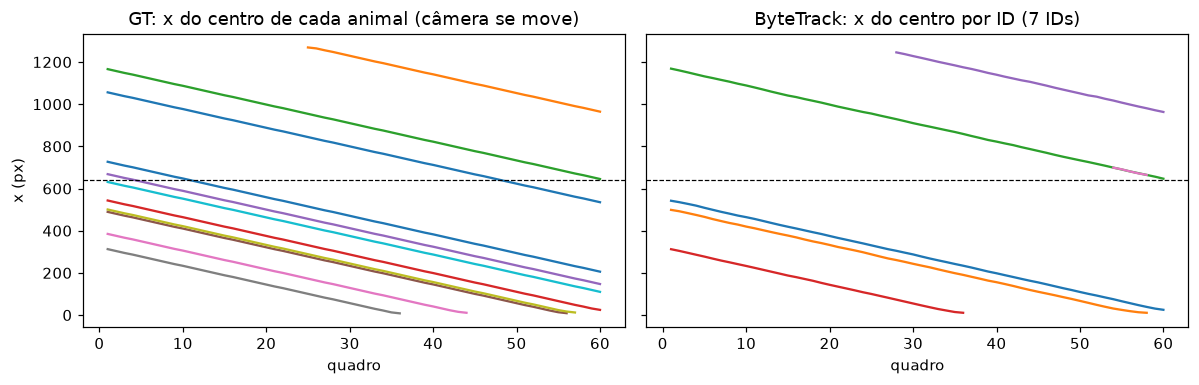

In [3]:
import cv2
from cattlecount.tracking import ByteTracker, TrackerConfig
z = np.load('../runs/tracking/synthetic_pan_full.npz', allow_pickle=True)['d']
gt = np.loadtxt('../sample_data/demo_pan_synthetic_gt.txt', delimiter=',')
tr = ByteTracker(TrackerConfig(high_thresh=.25, low_thresh=.1, new_track_thresh=.35))
out = {k: tr.update(d) for k, d in enumerate(z, 1)}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for g in sorted(set(gt[:, 1])):
    r = gt[gt[:, 1] == g]; ax[0].plot(r[:, 0], r[:, 2] + r[:, 4] / 2, lw=1.5)
ax[0].set_title('GT: x do centro de cada animal (câmera se move)'); ax[0].set_xlabel('quadro'); ax[0].set_ylabel('x (px)')
ids = sorted({int(r[4]) for rr in out.values() for r in rr})
for i in ids:
    pts = [(k, (r[0] + r[2]) / 2) for k, rr in out.items() for r in rr if int(r[4]) == i]
    ax[1].plot(*zip(*pts), lw=1.5)
ax[1].axhline(640, color='k', ls='--', lw=.8); ax[0].axhline(640, color='k', ls='--', lw=.8)
ax[1].set_title('ByteTrack: x do centro por ID (%d IDs)' % len(ids)); ax[1].set_xlabel('quadro'); plt.tight_layout(); plt.show()

## B · Vídeo terrestre real (Mendeley; GT de um clipe, viciado em detector COCO)

In [4]:
B = R['B_terrestre_mendeley']
print(B['aviso']); print('quadros:', B['n_frames'], '| animais no GT:', B['gt_ids'])
pd.DataFrame([{'método': k, 'HOTA': m['HOTA'], 'IDF1': m['IDF1'], 'MOTA': m['MOTA'], 'trocas ID': m['IDSW'], 'IDs previstos': m['n_pred_ids']} for k, m in B['metodos'].items()]).round(3)

GT de UM clipe (o arquivo tem 9 identidades; a descrição do autor cita 8 animais) gerado com YOLOv8-COCO+DeepSORT e corrigido: favorece detectores tipo COCO; não é GT aéreo
quadros: 479 | animais no GT: 9


,método,HOTA,IDF1,MOTA,trocas ID,IDs previstos
0,ByteTrack próprio,0.727,0.880,0.841,3,8
1,ByteTrack Ultralytics,0.731,0.892,0.837,2,8
2,Baseline IoU,0.691,0.739,0.853,22,34


**Leitura.** O ByteTrack próprio e o do Ultralytics (mesmas detecções, mesmos limiares) dão resultados praticamente iguais, o que valida a implementação própria; ambos superam o baseline IoU, que fragmenta muito (mais IDs e mais trocas). Atenção: o GT favorece detectores tipo COCO e o cenário é terrestre.